# Assignment 4
## Data Science
Name - Divyank Rajput
Roll No. - 2026010038
MCAB


## A. CSV File Handling


In [2]:
# Q1. Student Marks Analysis from CSV.
import csv

students = [
    ["Student_ID", "Name", "Python", "DBMS", "Maths", "Attendance"],
    [101, "Aman", 78, 82, 85, 88],
    [102, "Riya", 92, 89, 95, 91],
    [103, "Kabir", 45, 52, 48, 72],
    [104, "Neha", 86, 90, 84, 79],
    [105, "Arjun", 35, 42, 38, 68]
]

with open("student_marks.csv", "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerows(students)

records = []
with open("student_marks.csv", "r") as file:
    reader = csv.DictReader(file)
    for row in reader:
        row["Python"] = int(row["Python"])
        row["DBMS"] = int(row["DBMS"])
        row["Maths"] = int(row["Maths"])
        row["Attendance"] = float(row["Attendance"])
        row["Average"] = (row["Python"] + row["DBMS"] + row["Maths"]) / 3
        records.append(row)

print("Student Records:")
for student in records:
    print(student)

topper = max(records, key=lambda x: x["Average"])
print("\nHighest Average:", topper["Name"], round(topper["Average"], 2))

for subject in ["Python", "DBMS", "Maths"]:
    marks = [student[subject] for student in records]
    print(subject, "- Highest:", max(marks), "Lowest:", min(marks))

print("\nAttendance below 75%:")
for student in records:
    if student["Attendance"] < 75:
        print(student["Name"])

passed = sum(1 for student in records if student["Average"] >= 40)
failed = len(records) - passed
print("Passed =", passed)
print("Failed =", failed)

with open("student_analysis.csv", "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["Student_ID", "Name", "Average", "Attendance", "Result"])
    for student in records:
        result = "Pass" if student["Average"] >= 40 else "Fail"
        writer.writerow([student["Student_ID"], student["Name"],
                         round(student["Average"], 2), student["Attendance"], result])

print("Analysis saved to student_analysis.csv")


Student Records:
{'Student_ID': '101', 'Name': 'Aman', 'Python': 78, 'DBMS': 82, 'Maths': 85, 'Attendance': 88.0, 'Average': 81.66666666666667}
{'Student_ID': '102', 'Name': 'Riya', 'Python': 92, 'DBMS': 89, 'Maths': 95, 'Attendance': 91.0, 'Average': 92.0}
{'Student_ID': '103', 'Name': 'Kabir', 'Python': 45, 'DBMS': 52, 'Maths': 48, 'Attendance': 72.0, 'Average': 48.333333333333336}
{'Student_ID': '104', 'Name': 'Neha', 'Python': 86, 'DBMS': 90, 'Maths': 84, 'Attendance': 79.0, 'Average': 86.66666666666667}
{'Student_ID': '105', 'Name': 'Arjun', 'Python': 35, 'DBMS': 42, 'Maths': 38, 'Attendance': 68.0, 'Average': 38.333333333333336}

Highest Average: Riya 92.0
Python - Highest: 92 Lowest: 35
DBMS - Highest: 90 Lowest: 42
Maths - Highest: 95 Lowest: 38

Attendance below 75%:
Kabir
Arjun
Passed = 4
Failed = 1
Analysis saved to student_analysis.csv


In [3]:
# Q2. Employee Salary Analysis.
import csv

employees = [
    ["Emp_ID", "Name", "Department", "Basic_Salary", "Bonus", "Experience"],
    [1, "Aman", "IT", 60000, 8000, 6],
    [2, "Riya", "HR", 45000, 5000, 4],
    [3, "Kabir", "IT", 75000, 10000, 8],
    [4, "Neha", "Finance", 55000, 7000, 7],
    [5, "Arjun", "HR", 50000, 6000, 3]
]

with open("employees.csv", "w", newline="") as file:
    csv.writer(file).writerows(employees)

records = []
with open("employees.csv", "r") as file:
    reader = csv.DictReader(file)
    for row in reader:
        row["Basic_Salary"] = float(row["Basic_Salary"])
        row["Bonus"] = float(row["Bonus"])
        row["Experience"] = int(row["Experience"])
        row["Total_Salary"] = row["Basic_Salary"] + row["Bonus"]
        records.append(row)

highest = max(records, key=lambda x: x["Total_Salary"])
print("Highest-paid employee:", highest["Name"], highest["Total_Salary"])

departments = {}
for employee in records:
    dept = employee["Department"]
    departments.setdefault(dept, []).append(employee["Total_Salary"])

for dept, salaries in departments.items():
    print(dept, "Average Salary =", sum(salaries) / len(salaries))

print("\nEmployees with more than 5 years experience:")
for employee in records:
    if employee["Experience"] > 5:
        print(employee["Name"])

records.sort(key=lambda x: x["Total_Salary"], reverse=True)

with open("sorted_employees.csv", "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["Emp_ID", "Name", "Department", "Total_Salary", "Experience"])
    for employee in records:
        writer.writerow([employee["Emp_ID"], employee["Name"], employee["Department"],
                         employee["Total_Salary"], employee["Experience"]])

print("Sorted result saved to sorted_employees.csv")


Highest-paid employee: Kabir 85000.0
IT Average Salary = 76500.0
HR Average Salary = 53000.0
Finance Average Salary = 62000.0

Employees with more than 5 years experience:
Aman
Kabir
Neha
Sorted result saved to sorted_employees.csv


In [4]:
# Q3. Sales Data Analysis.
import csv

sales = [
    ["Order_ID", "Product", "Category", "Quantity", "Price", "Region"],
    [1, "Laptop", "Electronics", 2, 60000, "North"],
    [2, "Mouse", "Accessories", 10, 800, "South"],
    [3, "Keyboard", "Accessories", 5, 1500, "North"],
    [4, "Phone", "Electronics", 4, 30000, "West"],
    [5, "Laptop", "Electronics", 1, 62000, "East"],
    [6, "Mouse", "Accessories", 8, 850, "West"]
]

with open("sales.csv", "w", newline="") as file:
    csv.writer(file).writerows(sales)

records = []
with open("sales.csv", "r") as file:
    reader = csv.DictReader(file)
    for row in reader:
        row["Quantity"] = int(row["Quantity"])
        row["Price"] = float(row["Price"])
        row["Revenue"] = row["Quantity"] * row["Price"]
        records.append(row)

product_quantity = {}
product_revenue = {}
region_revenue = {}
category_sales = {}

for order in records:
    product = order["Product"]
    region = order["Region"]
    category = order["Category"]

    product_quantity[product] = product_quantity.get(product, 0) + order["Quantity"]
    product_revenue[product] = product_revenue.get(product, 0) + order["Revenue"]
    region_revenue[region] = region_revenue.get(region, 0) + order["Revenue"]
    category_sales[category] = category_sales.get(category, 0) + order["Revenue"]

print("Total sales for every order:")
for order in records:
    print("Order", order["Order_ID"], "=", order["Revenue"])

print("Best-selling product:", max(product_quantity, key=product_quantity.get))
print("Maximum revenue product:", max(product_revenue, key=product_revenue.get))
print("Region-wise revenue:", region_revenue)
print("Category-wise sales:", category_sales)

top5 = sorted(records, key=lambda x: x["Revenue"], reverse=True)[:5]
print("Top 5 orders:")
for order in top5:
    print(order["Order_ID"], order["Revenue"])

with open("sales_summary.csv", "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["Order_ID", "Product", "Revenue"])
    for order in top5:
        writer.writerow([order["Order_ID"], order["Product"], order["Revenue"]])

print("Summary saved to sales_summary.csv")


Total sales for every order:
Order 1 = 120000.0
Order 2 = 8000.0
Order 3 = 7500.0
Order 4 = 120000.0
Order 5 = 62000.0
Order 6 = 6800.0
Best-selling product: Mouse
Maximum revenue product: Laptop
Region-wise revenue: {'North': 127500.0, 'South': 8000.0, 'West': 126800.0, 'East': 62000.0}
Category-wise sales: {'Electronics': 302000.0, 'Accessories': 22300.0}
Top 5 orders:
1 120000.0
4 120000.0
5 62000.0
2 8000.0
3 7500.0
Summary saved to sales_summary.csv


In [5]:
# Q4. Weather Data Processing.
import csv

weather = [
    ["Date", "City", "Temperature", "Humidity", "Rainfall"],
    ["01-01-2026", "Delhi", 18, 65, 0],
    ["02-01-2026", "Delhi", 20, 72, 4],
    ["01-01-2026", "Mumbai", 27, 78, 8],
    ["02-01-2026", "Mumbai", 29, 82, 12],
    ["01-01-2026", "Pune", 23, 68, 0],
    ["02-01-2026", "Pune", 25, 74, 3]
]

with open("weather.csv", "w", newline="") as file:
    csv.writer(file).writerows(weather)

records = []
with open("weather.csv", "r") as file:
    reader = csv.DictReader(file)
    for row in reader:
        row["Temperature"] = float(row["Temperature"])
        row["Humidity"] = float(row["Humidity"])
        row["Rainfall"] = float(row["Rainfall"])
        records.append(row)

cities = {}
for row in records:
    cities.setdefault(row["City"], []).append(row)

for city, data in cities.items():
    avg_temp = sum(x["Temperature"] for x in data) / len(data)
    print(city, "Average Temperature =", avg_temp)

print("Maximum Temperature =", max(x["Temperature"] for x in records))
print("Minimum Temperature =", min(x["Temperature"] for x in records))

max_rain = max(records, key=lambda x: x["Rainfall"])
print("Day having maximum rainfall:", max_rain["Date"], max_rain["City"])

rainy_days = sum(1 for x in records if x["Rainfall"] > 0)
print("Rainy Days =", rainy_days)

print("Cities with average humidity above 70%:")
for city, data in cities.items():
    avg_humidity = sum(x["Humidity"] for x in data) / len(data)
    if avg_humidity > 70:
        print(city)

with open("city_statistics.csv", "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["City", "Average_Temperature", "Average_Humidity"])
    for city, data in cities.items():
        avg_temp = sum(x["Temperature"] for x in data) / len(data)
        avg_humidity = sum(x["Humidity"] for x in data) / len(data)
        writer.writerow([city, round(avg_temp, 2), round(avg_humidity, 2)])

print("Statistics saved to city_statistics.csv")


Delhi Average Temperature = 19.0
Mumbai Average Temperature = 28.0
Pune Average Temperature = 24.0
Maximum Temperature = 29.0
Minimum Temperature = 18.0
Day having maximum rainfall: 02-01-2026 Mumbai
Rainy Days = 4
Cities with average humidity above 70%:
Mumbai
Pune
Statistics saved to city_statistics.csv


In [6]:
# Q5. Movie Dataset Analysis.
import csv

movies = [
    ["Movie_ID", "Title", "Genre", "Year", "Rating", "Votes"],
    [1, "Movie A", "Drama", 2021, 8.5, 1200],
    [2, "Movie B", "Action", 2020, 7.8, 950],
    [3, "Movie C", "Drama", 2022, 9.1, 1800],
    [4, "Movie D", "Comedy", 2021, 7.5, 700],
    [5, "Movie E", "Action", 2023, 8.8, 1500],
    [6, "Movie F", "Drama", 2020, 8.2, 1100]
]

with open("movies.csv", "w", newline="") as file:
    csv.writer(file).writerows(movies)

records = []
with open("movies.csv", "r") as file:
    reader = csv.DictReader(file)
    for row in reader:
        row["Year"] = int(row["Year"])
        row["Rating"] = float(row["Rating"])
        records.append(row)

highest = max(records, key=lambda x: x["Rating"])
print("Highest-rated movie:", highest["Title"])

top10 = sorted(records, key=lambda x: x["Rating"], reverse=True)[:10]
print("Top movies:")
for movie in top10:
    print(movie["Title"], movie["Rating"])

genres = {}
years = {}
for movie in records:
    genres.setdefault(movie["Genre"], []).append(movie["Rating"])
    years[movie["Year"]] = years.get(movie["Year"], 0) + 1

for genre, ratings in genres.items():
    print(genre, "Average Rating =", sum(ratings) / len(ratings))

print("Movies released each year:", years)

print("Genres having more than 20 movies:")
for genre, ratings in genres.items():
    if len(ratings) > 20:
        print(genre)

with open("top_rated_movies.csv", "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["Movie_ID", "Title", "Genre", "Year", "Rating"])
    for movie in top10:
        writer.writerow([movie["Movie_ID"], movie["Title"], movie["Genre"],
                         movie["Year"], movie["Rating"]])

print("Top-rated movies saved to top_rated_movies.csv")


Highest-rated movie: Movie C
Top movies:
Movie C 9.1
Movie E 8.8
Movie A 8.5
Movie F 8.2
Movie B 7.8
Movie D 7.5
Drama Average Rating = 8.6
Action Average Rating = 8.3
Comedy Average Rating = 7.5
Movies released each year: {2021: 2, 2020: 2, 2022: 1, 2023: 1}
Genres having more than 20 movies:
Top-rated movies saved to top_rated_movies.csv


## B. NumPy


In [7]:
# Q6. Student Marks Using NumPy.
import numpy as np

marks = np.array([
    [78, 82, 85, 74, 88],
    [92, 89, 95, 91, 90],
    [65, 70, 68, 72, 69],
    [86, 84, 90, 88, 85],
    [55, 60, 58, 62, 57],
    [73, 76, 80, 75, 78],
    [88, 91, 87, 90, 92],
    [69, 72, 74, 70, 71],
    [81, 85, 83, 86, 84],
    [60, 64, 62, 66, 63]
])

subject_avg = np.mean(marks, axis=0)
student_avg = np.mean(marks, axis=1)
overall_avg = np.mean(marks)

print("Subject-wise Average:", subject_avg)
print("Student-wise Average:", student_avg)
print("Highest Mark:", np.max(marks))
print("Lowest Mark:", np.min(marks))
print("Students above overall average:", np.where(student_avg > overall_avg)[0] + 1)
print("Subject-wise Standard Deviation:", np.std(marks, axis=0))

order = np.argsort(student_avg)[::-1]
print("Students sorted by average:", order + 1)
print("Top 3 Students:", order[:3] + 1)


Subject-wise Average: [74.7 77.3 78.2 77.4 77.7]
Student-wise Average: [81.4 91.4 68.8 86.6 58.4 76.4 89.6 71.2 83.8 63. ]
Highest Mark: 95
Lowest Mark: 55
Students above overall average: [1 2 4 7 9]
Subject-wise Standard Deviation: [11.78176557 10.05037313 11.67732846  9.9919968  11.48956048]
Students sorted by average: [ 2  7  4  9  1  6  8  3 10  5]
Top 3 Students: [2 7 4]


In [8]:
# Q7. Employee Salary Statistics Using NumPy.
import numpy as np

salaries = np.array([35000, 42000, 50000, 62000, 75000, 81000, 58000, 47000, 90000, 68000])

print("Mean Salary =", np.mean(salaries))
print("Median Salary =", np.median(salaries))
print("Maximum Salary =", np.max(salaries))
print("Minimum Salary =", np.min(salaries))
print("Standard Deviation =", np.std(salaries))
print("Above Average =", salaries[salaries > np.mean(salaries)])
print("Between 40000 and 80000 =", salaries[(salaries >= 40000) & (salaries <= 80000)])

percentage = np.sum(salaries > 60000) / len(salaries) * 100
print("Percentage above 60000 =", percentage, "%")


Mean Salary = 60800.0
Median Salary = 60000.0
Maximum Salary = 90000
Minimum Salary = 35000
Standard Deviation = 16880.758276807355
Above Average = [62000 75000 81000 90000 68000]
Between 40000 and 80000 = [42000 50000 62000 75000 58000 47000 68000]
Percentage above 60000 = 50.0 %


In [9]:
# Q8. Matrix Operations.
import numpy as np

A = np.array([
    [2, 1, 3],
    [1, 0, 2],
    [4, 1, 8]
])

B = np.array([
    [1, 2, 1],
    [3, 1, 2],
    [2, 4, 1]
])

print("Addition:\n", A + B)
print("Subtraction:\n", A - B)
print("Element-wise Multiplication:\n", A * B)
print("Matrix Multiplication:\n", A @ B)
print("Transpose of A:\n", A.T)
print("Row-wise Sum:", np.sum(A, axis=1))
print("Column-wise Sum:", np.sum(A, axis=0))
print("Maximum Element:", np.max(A))
print("Minimum Element:", np.min(A))
print("Determinant:", np.linalg.det(A))

if not np.isclose(np.linalg.det(A), 0):
    print("Inverse:\n", np.linalg.inv(A))
else:
    print("Inverse is not possible.")


Addition:
 [[3 3 4]
 [4 1 4]
 [6 5 9]]
Subtraction:
 [[ 1 -1  2]
 [-2 -1  0]
 [ 2 -3  7]]
Element-wise Multiplication:
 [[2 2 3]
 [3 0 4]
 [8 4 8]]
Matrix Multiplication:
 [[11 17  7]
 [ 5 10  3]
 [23 41 14]]
Transpose of A:
 [[2 1 4]
 [1 0 1]
 [3 2 8]]
Row-wise Sum: [ 6  3 13]
Column-wise Sum: [ 7  2 13]
Maximum Element: 8
Minimum Element: 0
Determinant: -1.0
Inverse:
 [[ 2.  5. -2.]
 [ 0. -4.  1.]
 [-1. -2.  1.]]


In [10]:
# Q9. Electricity Consumption Analysis.
import numpy as np

months = np.array(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                   "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
consumption = np.array([320, 300, 340, 360, 410, 450, 480, 470, 420, 390, 350, 330])

annual = np.sum(consumption)
average = np.mean(consumption)

print("Annual Consumption =", annual)
print("Monthly Average =", average)
print("Highest Consumption Month =", months[np.argmax(consumption)])
print("Lowest Consumption Month =", months[np.argmin(consumption)])
print("Months Above Average =", months[consumption > average])
print("Standard Deviation =", np.std(consumption))
print("Percentage Contribution =", consumption / annual * 100)

order = np.argsort(consumption)[::-1]
print("Months sorted by consumption:")
for i in order:
    print(months[i], consumption[i])


Annual Consumption = 4620
Monthly Average = 385.0
Highest Consumption Month = Jul
Lowest Consumption Month = Feb
Months Above Average = ['May' 'Jun' 'Jul' 'Aug' 'Sep' 'Oct']
Standard Deviation = 58.23801736552049
Percentage Contribution = [ 6.92640693  6.49350649  7.35930736  7.79220779  8.87445887  9.74025974
 10.38961039 10.17316017  9.09090909  8.44155844  7.57575758  7.14285714]
Months sorted by consumption:
Jul 480
Aug 470
Jun 450
Sep 420
May 410
Oct 390
Apr 360
Nov 350
Mar 340
Dec 330
Jan 320
Feb 300


In [11]:
# Q10. Image-Like Matrix Processing.
import numpy as np

image = np.array([
    [20, 60, 120, 180, 220],
    [30, 80, 130, 190, 240],
    [40, 90, 140, 200, 250],
    [50, 100, 150, 210, 255]
])

print("Minimum Pixel =", np.min(image))
print("Maximum Pixel =", np.max(image))
print("Mean Intensity =", np.mean(image))

threshold = 128
binary = np.where(image >= threshold, 255, 0)
print("Binary Image:\n", binary)

print("Specific Region:\n", image[1:3, 1:4])
print("Horizontal Flip:\n", np.fliplr(image))
print("Vertical Flip:\n", np.flipud(image))
print("Row-wise Intensity:", np.sum(image, axis=1))
print("Column-wise Intensity:", np.sum(image, axis=0))


Minimum Pixel = 20
Maximum Pixel = 255
Mean Intensity = 137.75
Binary Image:
 [[  0   0   0 255 255]
 [  0   0 255 255 255]
 [  0   0 255 255 255]
 [  0   0 255 255 255]]
Specific Region:
 [[ 80 130 190]
 [ 90 140 200]]
Horizontal Flip:
 [[220 180 120  60  20]
 [240 190 130  80  30]
 [250 200 140  90  40]
 [255 210 150 100  50]]
Vertical Flip:
 [[ 50 100 150 210 255]
 [ 40  90 140 200 250]
 [ 30  80 130 190 240]
 [ 20  60 120 180 220]]
Row-wise Intensity: [600 670 720 765]
Column-wise Intensity: [140 330 540 780 965]


## C. Matplotlib


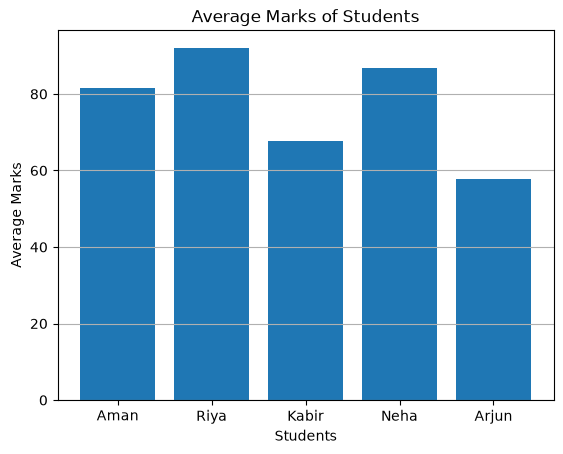

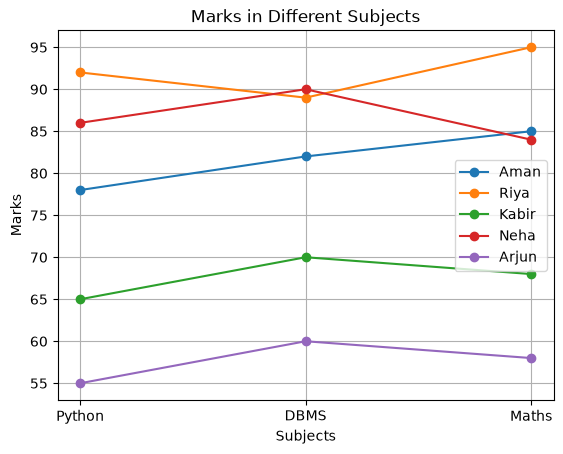

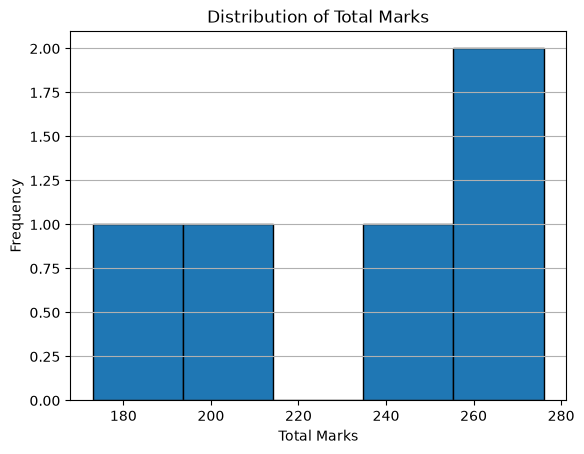

In [12]:
# Q11. Student Performance Visualization.
import numpy as np
import matplotlib.pyplot as plt

students = ["Aman", "Riya", "Kabir", "Neha", "Arjun"]
subjects = ["Python", "DBMS", "Maths"]
marks = np.array([
    [78, 82, 85],
    [92, 89, 95],
    [65, 70, 68],
    [86, 90, 84],
    [55, 60, 58]
])

averages = np.mean(marks, axis=1)

plt.bar(students, averages)
plt.title("Average Marks of Students")
plt.xlabel("Students")
plt.ylabel("Average Marks")
plt.grid(axis="y")
plt.show()

for i, student in enumerate(students):
    plt.plot(subjects, marks[i], marker="o", label=student)

plt.title("Marks in Different Subjects")
plt.xlabel("Subjects")
plt.ylabel("Marks")
plt.legend()
plt.grid()
plt.show()

totals = np.sum(marks, axis=1)
plt.hist(totals, bins=5, edgecolor="black")
plt.title("Distribution of Total Marks")
plt.xlabel("Total Marks")
plt.ylabel("Frequency")
plt.grid(axis="y")
plt.show()


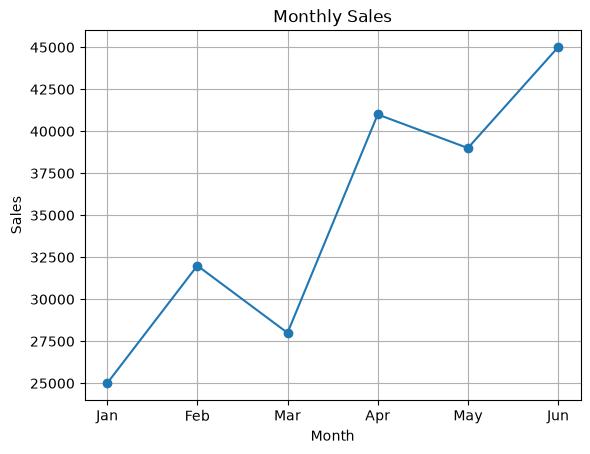

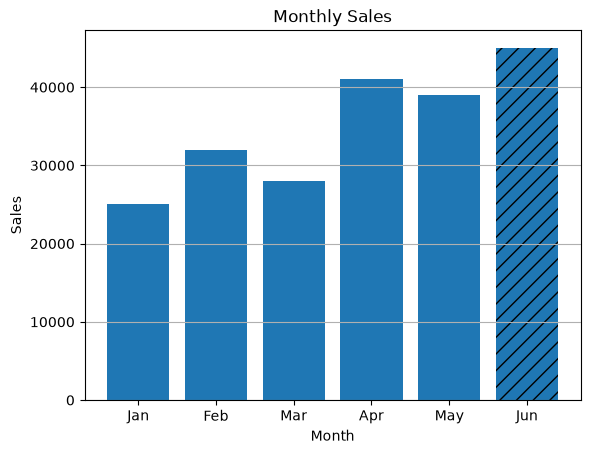

In [13]:
# Q12. Monthly Sales Visualization.
import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [25000, 32000, 28000, 41000, 39000, 45000]

plt.plot(months, sales, marker="o")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid()
plt.show()

bars = plt.bar(months, sales)
highest = sales.index(max(sales))
bars[highest].set_hatch("//")

plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid(axis="y")
plt.show()


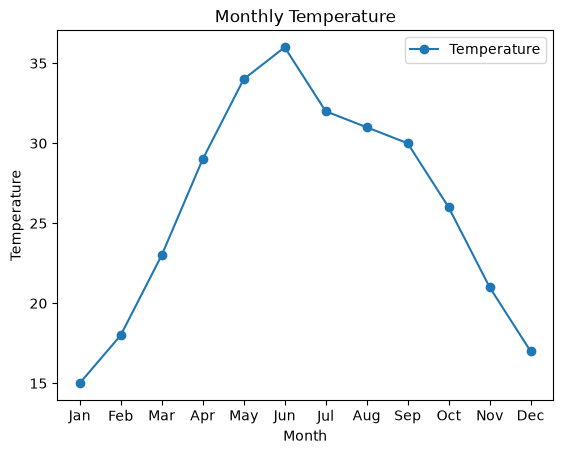

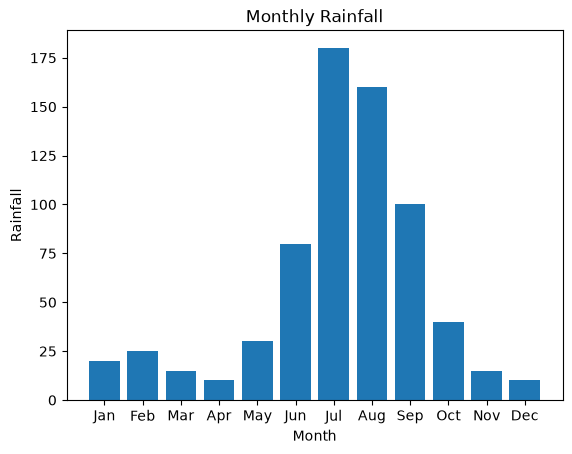

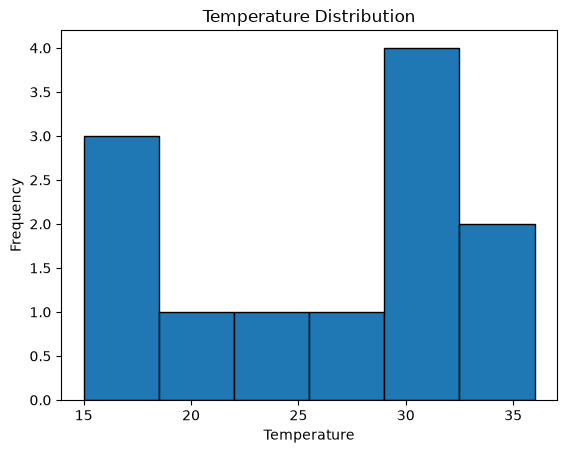

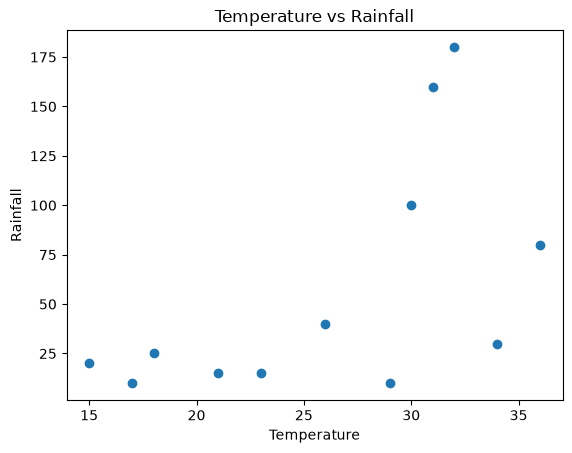

In [14]:
# Q13. Weather Visualization.
import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
temperature = [15, 18, 23, 29, 34, 36, 32, 31, 30, 26, 21, 17]
rainfall = [20, 25, 15, 10, 30, 80, 180, 160, 100, 40, 15, 10]

plt.plot(months, temperature, marker="o", label="Temperature")
plt.title("Monthly Temperature")
plt.xlabel("Month")
plt.ylabel("Temperature")
plt.legend()
plt.show()

plt.bar(months, rainfall)
plt.title("Monthly Rainfall")
plt.xlabel("Month")
plt.ylabel("Rainfall")
plt.show()

plt.hist(temperature, bins=6, edgecolor="black")
plt.title("Temperature Distribution")
plt.xlabel("Temperature")
plt.ylabel("Frequency")
plt.show()

plt.scatter(temperature, rainfall)
plt.title("Temperature vs Rainfall")
plt.xlabel("Temperature")
plt.ylabel("Rainfall")
plt.show()


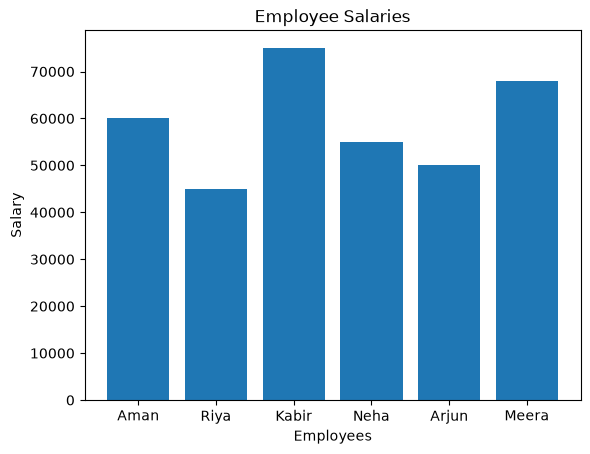

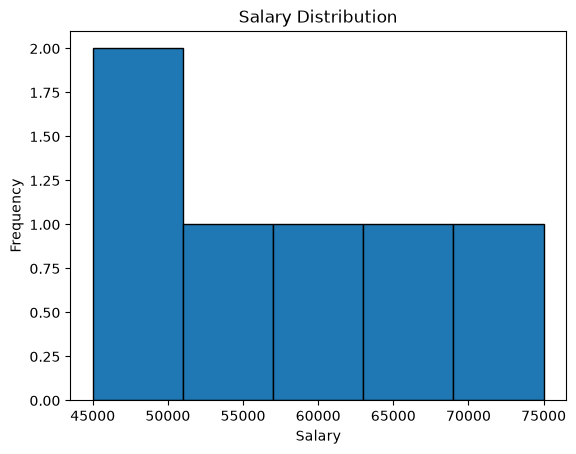

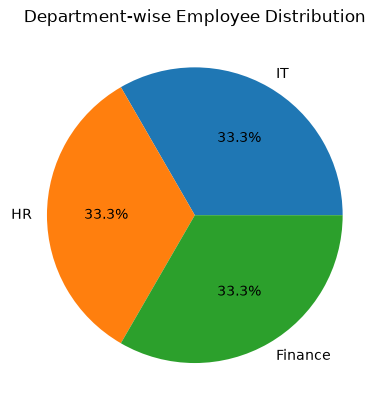

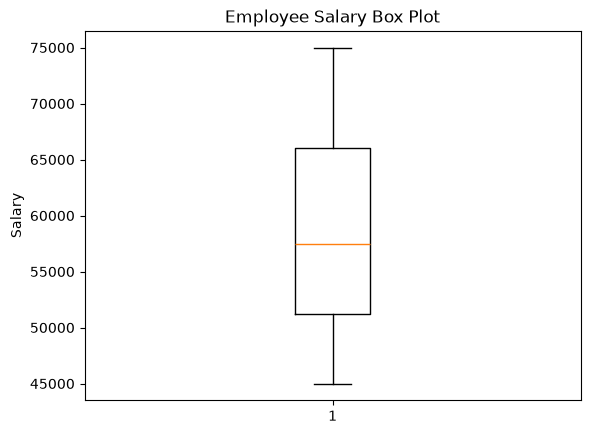

In [15]:
# Q14. Employee Salary Visualization.
import matplotlib.pyplot as plt

employees = ["Aman", "Riya", "Kabir", "Neha", "Arjun", "Meera"]
salaries = [60000, 45000, 75000, 55000, 50000, 68000]
departments = ["IT", "HR", "IT", "Finance", "HR", "Finance"]

plt.bar(employees, salaries)
plt.title("Employee Salaries")
plt.xlabel("Employees")
plt.ylabel("Salary")
plt.show()

plt.hist(salaries, bins=5, edgecolor="black")
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.show()

department_count = {}
for department in departments:
    department_count[department] = department_count.get(department, 0) + 1

plt.pie(department_count.values(), labels=department_count.keys(), autopct="%1.1f%%")
plt.title("Department-wise Employee Distribution")
plt.show()

plt.boxplot(salaries)
plt.title("Employee Salary Box Plot")
plt.ylabel("Salary")
plt.show()
